Task 2.1

In [434]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def data_generator(n_samples=10, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.sort(np.random.uniform(0, 0.5, n_samples))
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y

data = data_generator(n_samples=10, m=1, k=500, mu=5)

data

(array([0.02904181, 0.07799726, 0.07800932, 0.18727006, 0.29932924,
        0.30055751, 0.35403629, 0.36599697, 0.43308807, 0.47535715]),
 array([ 0.80588718, -0.04163497, -0.04185532, -0.38790979,  0.4606251 ,
         0.45576153,  0.04111211, -0.06684187, -0.33953227, -0.15894969]))

In [435]:
import torch
from torch import nn
import torch.nn.functional as F


num_hidden = 100
num_features = 1
num_output = 1

class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()
        # Setting up variables, these variables are weights in your 
        # network that can be updated while running our graph.
        # Notice, to make a hidden layer, the weights need to have the 
        # following dimensionality:
        #   W[number_of_units_going_out, number_of_units_going_in]
        #   b[number_of_units_going_out]
        # in the example below we have 2 input units (num_features) and 2 output units (num_output)
        # so our weights become W[2, 2], b[2]
        # if we want to make a hidden layer with 100 units, we need to define the shape of the
        # first weight to W[100, 2], b[100] and the shape of the second weight to W[2, 100], b[2]
        
        # first layer
        self.W_1 = nn.Parameter(torch.randn(num_hidden, num_features)) 
        self.b_1 = nn.Parameter(torch.randn(num_hidden))
        
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        self.W_2 = nn.Parameter(torch.randn(num_output, num_hidden))
        self.b_2 = nn.Parameter(torch.randn(num_output))
        
        
    def forward(self, x):
        # Setting up ops, these ops will define edges along our computational graph
        # The below ops will compute a logistic regression, 
        # but can be modified to compute a neural network
        x = F.linear(x, self.W_1, self.b_1)
        
        # second layer (to be completed as an exercise)
        x = F.tanh(x)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        x = F.linear(x, self.W_2, self.b_2)
        return x 

net = Net()

In [436]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.005)


In [437]:



num_epochs = 10000
train_losses = []

# Convert data to tensors
tr_input = torch.from_numpy(data[0]).float().reshape(-1, 1)
print(tr_input)
tr_targets = torch.from_numpy(data[1]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    # Prediction
    tr_output = net(tr_input)

    # Calculate loss
    tr_loss = criterion(tr_output, tr_targets)

    # Backpropagation
    tr_loss.backward()

    # Update weights
    optimizer.step()

    train_losses.append(tr_loss.data.numpy())

    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.item()))
print()

tensor([[0.0290],
        [0.0780],
        [0.0780],
        [0.1873],
        [0.2993],
        [0.3006],
        [0.3540],
        [0.3660],
        [0.4331],
        [0.4754]])
Epoch 0, Train Cost: 37.279785
Epoch 100, Train Cost: 0.125302
Epoch 200, Train Cost: 0.115840
Epoch 300, Train Cost: 0.115548
Epoch 400, Train Cost: 0.115217
Epoch 500, Train Cost: 0.114860
Epoch 600, Train Cost: 0.114489
Epoch 700, Train Cost: 0.114111
Epoch 800, Train Cost: 0.113732
Epoch 900, Train Cost: 0.113357
Epoch 1000, Train Cost: 0.112987
Epoch 1100, Train Cost: 0.112626
Epoch 1200, Train Cost: 0.112273
Epoch 1300, Train Cost: 0.111927
Epoch 1400, Train Cost: 0.111588
Epoch 1500, Train Cost: 0.111254
Epoch 1600, Train Cost: 0.110923
Epoch 1700, Train Cost: 0.110593
Epoch 1800, Train Cost: 0.110260
Epoch 1900, Train Cost: 0.109921
Epoch 2000, Train Cost: 0.109573
Epoch 2100, Train Cost: 0.109211
Epoch 2200, Train Cost: 0.108828
Epoch 2300, Train Cost: 0.108416
Epoch 2400, Train Cost: 0.107958
Epoch

In [438]:
np.random.seed(42)

def data_generator(n_samples=100, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.linspace(0, 1, n_samples+2)[1:-1]

    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y

colloc_data = data_generator(n_samples=100, m=1, k=500, mu=5)


In [439]:

plotting_data = data_generator(n_samples=100, m=1, k=500, mu=5)


In [440]:
te_input = torch.from_numpy(plotting_data[0]).float().reshape(-1, 1)
te_target = torch.from_numpy(plotting_data[1]).float().reshape(-1, 1)


with torch.no_grad():
    te_output = net(te_input)




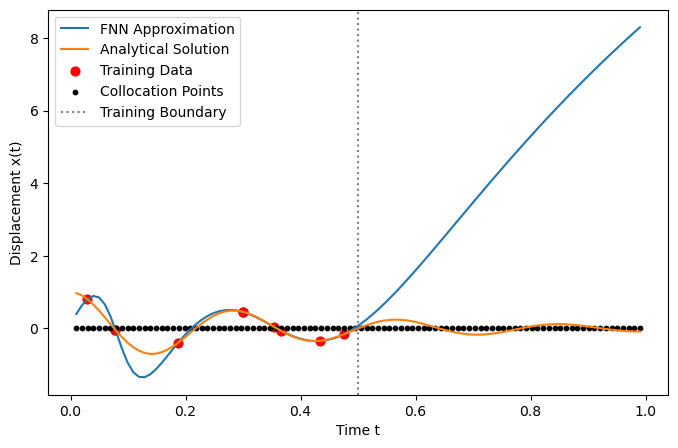

In [441]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(te_input,te_output, label="FNN Approximation")
plt.plot(te_input,te_target, label="Analytical Solution")
plt.scatter(data[0], data[1], color="red", label="Training Data", s=40)
plt.scatter(colloc_data[0], np.zeros(len(colloc_data[0])), color="black", label="Collocation Points", s=10)
plt.axvline(0.5, color="gray", linestyle=":", label="Training Boundary")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()






it gets crazy since the net is only trained on the interval 0-0.5, so it does not know at all after this. 

In [442]:

def loss(net, data_input, data_target, colloc_input, lambda_phys=1.0, lambda_IC=1.0):

    data_out= net(data_input)
    colloc_out=net(colloc_input)

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    a=F.linear(colloc_input, W1, b1)

    L_data= nn.MSELoss()(data_out,data_target)

    tanh_a= torch.tanh(a)
    tanh_a_d= 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d

   
    x_d= (W2 * tanh_a_d) @ W1

    x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

    residual = x_dd + 5*x_d + 500*colloc_out

    L_phys = nn.MSELoss()(residual, torch.zeros_like(residual))

 

    L_IC1= ((W2@torch.tanh(b1)+b2)-1)**2

    L_IC2= (W2*(1 - torch.tanh(b1)**2)@W1)**2

    L_IC= L_IC1 + L_IC2

    L_total= L_data + lambda_phys*L_phys + lambda_IC*L_IC

    return L_data, L_phys, L_IC, L_total



In [443]:
## finite difference calculations


data_input=torch.from_numpy(data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(colloc_data[0]).float().reshape(-1, 1)


net = Net()

epsilon= 10**(-5)

with torch.no_grad():
    net.W_1[4,0]=net.W_1[4,0]+epsilon

loss_plus = loss(net, data_input, data_target, colloc_input, lambda_phys=1.0, lambda_IC=1.0)[3]

with torch.no_grad():
    net.W_1[4,0]=net.W_1[4,0]-2*epsilon

loss_minus = loss(net, data_input, data_target, colloc_input, lambda_phys=1.0, lambda_IC=1.0)[3]

loss_approx = (loss_plus- loss_minus)/(2*epsilon)

loss_approx



tensor([[-1450000.]], grad_fn=<DivBackward0>)

In [448]:
## Analytical gradient calculations

## gradient of loss w.r.t W1

with torch.no_grad():
    net.W_1[4,0]=net.W_1[4,0]+epsilon

W1 = net.W_1
W2 = net.W_2
b1 = net.b_1
b2 = net.b_2

data_out= net(data_input)
colloc_out = net(colloc_input)

a=F.linear(colloc_input, W1, b1)

b=F.linear(data_input, W1, b1)


tanh_a= torch.tanh(a)
tanh_a_d= 1 - tanh_a**2
tanh_a_dd = -2*tanh_a*tanh_a_d
tanh_a_ddd = -2*tanh_a_d**2 -2*tanh_a*tanh_a_dd

tanh_b= torch.tanh(b)
tanh_b_d= 1 - tanh_b**2
tanh_b_dd = -2*tanh_b*tanh_b_d
tanh_b_ddd = -2*tanh_b_d**2 -2*tanh_b*tanh_b_dd

   
x_d= (W2 * tanh_a_d) @ W1
x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

residual = x_dd + 5*x_d + 500*colloc_out



r1_d_W1 = (W2 * tanh_a_dd * W1.T+ W1.T * (W2 * tanh_a_dd+ W2 * tanh_a_ddd * colloc_input * W1.T))


r2_d_W1 = 5*((W2*tanh_a_d) + W2*tanh_a_dd*colloc_input*W1.T)



r3_d_W1 = 500*(W2*tanh_a_d)*colloc_input



residual_d_W1= r1_d_W1 + r2_d_W1 + r3_d_W1


lambda_phys=1
lambda_IC= 1

##g_data_W1 = 2*torch.mean((data_out-data_target)*((W2*tanh_b_d).T*data_input), dim=0)

g_data_W1 = 2 * torch.mean((data_out - data_target) *(W2 * tanh_b_d) *data_input,dim=0).reshape_as(W1)

g_phys_W1 = 2*torch.mean(residual*residual_d_W1, dim=0).reshape_as(W1)

g_IC1_W1 = torch.zeros_like(W1)


g_IC2_W1 = (2*((W2*(1 - torch.tanh(b1)**2)) @ W1)* (W2 * (1 - torch.tanh(b1)**2)).T)

g_IC_W1= g_IC1_W1 + g_IC2_W1

g_total_W1 = g_data_W1 + lambda_phys*g_phys_W1 + lambda_IC*g_IC_W1 

print(g_total_W1[4,0])

print("W1:", W1.shape)
print("Data:", g_data_W1.shape)
print("Physics:", g_phys_W1.shape)
print("IC:", g_IC_W1.shape)
print("Total:", g_total_W1.shape)

tensor(-39206.4727, grad_fn=<SelectBackward0>)
W1: torch.Size([100, 1])
Data: torch.Size([100, 1])
Physics: torch.Size([100, 1])
IC: torch.Size([100, 1])
Total: torch.Size([100, 1])


In [447]:
## Analytical gradient calculations

## gradient of loss w.r.t W2

data_input=torch.from_numpy(data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(colloc_data[0]).float().reshape(-1, 1)


net = Net()


W1 = net.W_1
W2 = net.W_2
b1 = net.b_1
b2 = net.b_2

data_out= net(data_input)
colloc_out = net(colloc_input)

a=F.linear(colloc_input, W1, b1)

b=F.linear(data_input, W1, b1)


tanh_a= torch.tanh(a)
tanh_a_d= 1 - tanh_a**2
tanh_a_dd = -2*tanh_a*tanh_a_d
tanh_a_ddd = -2*tanh_a_d**2 -2*tanh_a*tanh_a_dd

tanh_b= torch.tanh(b)
tanh_b_d= 1 - tanh_b**2
tanh_b_dd = -2*tanh_b*tanh_b_d
tanh_b_ddd = -2*tanh_b_d**2 -2*tanh_b*tanh_b_dd

   
x_d= (W2 * tanh_a_d) @ W1
x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

residual = x_dd + 5*x_d + 500*colloc_out



r1_d_W2 = W1.T**2* (tanh_a_dd)


r2_d_W2 = 5*(tanh_a_d*W1.T)



r3_d_W2 = 500*(tanh_a)



residual_d_W2= r1_d_W2 + r2_d_W2 + r3_d_W2


lambda_phys=1.0
lambda_IC= 1.0



g_data_W2 = 2 * torch.mean((data_out - data_target) * tanh_b,dim=0).reshape_as(W2)

g_phys_W2 = 2*torch.mean(residual*residual_d_W2, dim=0).reshape_as(W2)


g_IC1_W2 = (2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)* torch.tanh(b1).reshape(1, -1))


g_IC2_W2 = (2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)* ((1 - torch.tanh(b1)**2) * W1.T))

g_IC_W2= g_IC1_W2 + g_IC2_W2

g_total_W2 = g_data_W2 + lambda_phys*g_phys_W2 + lambda_IC*g_IC_W2 

print("W2:", W2.shape)
print("Data:", g_data_W2.shape)
print("Physics:", g_phys_W2.shape)
print("IC1:", g_IC1_W2.shape)
print("IC2:", g_IC2_W2.shape)
print("Total:", g_total_W2.shape)





W2: torch.Size([1, 100])
Data: torch.Size([1, 100])
Physics: torch.Size([1, 100])
IC1: torch.Size([1, 100])
IC2: torch.Size([1, 100])
Total: torch.Size([1, 100])


In [ ]:
## Analytical gradient calculations

## gradient of loss w.r.t b1

data_input=torch.from_numpy(data_data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data_data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(data_colloc[0]).float().reshape(-1, 1)


net = Net()


W1 = net.W_1
W2 = net.W_2
b1 = net.b_1
b2 = net.b_2

data_out= net(data_input)
colloc_out = net(colloc_input)

a=F.linear(colloc_input, W1, b1)

b=F.linear(data_input, W1, b1)


tanh_a= torch.tanh(a)
tanh_a_d= 1 - tanh_a**2
tanh_a_dd = -2*tanh_a*tanh_a_d
tanh_a_ddd = -2*tanh_a_d**2 -2*tanh_a*tanh_a_dd

tanh_b= torch.tanh(b)
tanh_b_d= 1 - tanh_b**2
tanh_b_dd = -2*tanh_b*tanh_b_d
tanh_b_ddd = -2*tanh_b_d**2 -2*tanh_b*tanh_b_dd

   
x_d= (W2 * tanh_a_d) @ W1
x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

residual = x_dd + 5*x_d + 500*colloc_out



r1_d_b1 = W1.T**2* W2*(tanh_a_ddd)


r2_d_b1 = 5*W2*tanh_a_dd*W1.T



r3_d_b1 = 500*(W2*tanh_a_d)



residual_d_b1= r1_d_b1 + r2_d_b1 + r3_d_b1


lambda_phys=1.0
lambda_IC= 1.0



g_data_b1 = 2 * torch.mean((data_out - data_target) * W2*tanh_b_d,dim=0).reshape_as(b1)

g_phys_b1 = 2*torch.mean(residual*residual_d_b1, dim=0).reshape_as(b1)


g_IC1_b1 = (2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)* W2*(1 - torch.tanh(b1)**2)).reshape_as(b1)


g_IC2_b1 = (2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)* (W2*(-2*(torch.tanh(b1))*(1 - torch.tanh(b1)**2)) * W1.T)).reshape_as(b1)

g_IC_b1= g_IC1_b1 + g_IC2_b1

g_total_b1 = g_data_b1 + lambda_phys*g_phys_b1 + lambda_IC*g_IC_b1 

print("b1:", b1.shape)
print("Data:", g_data_b1.shape)
print("Physics:", g_phys_b1.shape)
print("IC1:", g_IC1_b1.shape)
print("IC2:", g_IC2_b1.shape)
print("Total:", g_total_b1.shape)





b1: torch.Size([100])
Data: torch.Size([100])
Physics: torch.Size([100])
IC1: torch.Size([100])
IC2: torch.Size([100])
Total: torch.Size([100])


In [ ]:
## Analytical gradient calculations

## gradient of loss w.r.t b2

data_input=torch.from_numpy(data_data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data_data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(data_colloc[0]).float().reshape(-1, 1)


net = Net()


W1 = net.W_1
W2 = net.W_2
b1 = net.b_1
b2 = net.b_2

data_out= net(data_input)
colloc_out = net(colloc_input)

a=F.linear(colloc_input, W1, b1)

b=F.linear(data_input, W1, b1)


tanh_a= torch.tanh(a)
tanh_a_d= 1 - tanh_a**2
tanh_a_dd = -2*tanh_a*tanh_a_d
tanh_a_ddd = -2*tanh_a_d**2 -2*tanh_a*tanh_a_dd

tanh_b= torch.tanh(b)
tanh_b_d= 1 - tanh_b**2
tanh_b_dd = -2*tanh_b*tanh_b_d
tanh_b_ddd = -2*tanh_b_d**2 -2*tanh_b*tanh_b_dd

   
x_d= (W2 * tanh_a_d) @ W1
x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

residual = x_dd + 5*x_d + 500*colloc_out



r1_d_b2 = 0


r2_d_b2 = 0



r3_d_b2 = 500*1



residual_d_b2= r1_d_b2 + r2_d_b2 + r3_d_b2


lambda_phys=1.0
lambda_IC= 1.0



g_data_b2 = 2 * torch.mean((data_out - data_target), dim=0)

g_phys_b2 = 2*torch.mean(residual*residual_d_b2, dim=0)


g_IC1_b2 = (2 * (W2 @ torch.tanh(b1) + b2 - 1)* 1)


g_IC2_b2 = torch.zeros_like(b2)

g_IC_b2= g_IC1_b2 + g_IC2_b2

g_total_b2 = g_data_b2 + lambda_phys*g_phys_b2 + lambda_IC*g_IC_b2 

print("b2:", b2.shape)
print("Data:", g_data_b2.shape)
print("Physics:", g_phys_b2.shape)
print("IC1:", g_IC1_b2.shape)
print("IC2:", g_IC2_b2.shape)
print("Total:", g_total_b2.shape)

b2: torch.Size([1])
Data: torch.Size([1])
Physics: torch.Size([1])
IC1: torch.Size([1])
IC2: torch.Size([1])
Total: torch.Size([1])


In [ ]:
# Her samler vi bare de analystiske gradienter vi lavede før i en funktion der regner dem alle på en gang.

def analytical_grads(net, data_input, data_target, colloc_input,
                     lambda_phys=1.0, lambda_IC=1.0):

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    data_out = net(data_input)
    colloc_out = net(colloc_input)

    a = F.linear(colloc_input, W1, b1)
    b = F.linear(data_input, W1, b1)

    tanh_a = torch.tanh(a)
    tanh_a_d = 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d
    tanh_a_ddd = -2*tanh_a_d**2 - 2*tanh_a*tanh_a_dd

    tanh_b = torch.tanh(b)
    tanh_b_d = 1 - tanh_b**2

    x_d = (W2 * tanh_a_d) @ W1
    x_dd = ((W1.T * W2) * tanh_a_dd) @ W1

    residual = x_dd + 5*x_d + 500*colloc_out

    ## gradient of loss w.r.t W1

    r1_d_W1 = (W2 * tanh_a_dd * W1.T + W1.T * (W2 * tanh_a_dd + W2 * tanh_a_ddd * colloc_input * W1.T))
    r2_d_W1 = 5*((W2*tanh_a_d) + W2*tanh_a_dd*colloc_input*W1.T)
    r3_d_W1 = 500*(W2*tanh_a_d)*colloc_input

    residual_d_W1 = r1_d_W1 + r2_d_W1 + r3_d_W1

    g_data_W1 = 2 * torch.mean((data_out - data_target) * (W2 * tanh_b_d) * data_input, dim=0).reshape_as(W1)
    g_phys_W1 = 2 * torch.mean(residual*residual_d_W1, dim=0).reshape_as(W1)

    g_IC1_W1 = torch.zeros_like(W1)
    g_IC2_W1 = (2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)* (W2 * (1 - torch.tanh(b1)**2)).T)
    g_IC_W1 = g_IC1_W1 + g_IC2_W1

    g_total_W1 = g_data_W1 + lambda_phys*g_phys_W1 + lambda_IC*g_IC_W1
    

    ## gradient of loss w.r.t W2

    r1_d_W2 = W1.T**2 * tanh_a_dd
    r2_d_W2 = 5*(tanh_a_d*W1.T)
    r3_d_W2 = 500*tanh_a

    residual_d_W2 = r1_d_W2 + r2_d_W2 + r3_d_W2

    g_data_W2 = 2 * torch.mean((data_out - data_target) * tanh_b, dim=0).reshape_as(W2)
    g_phys_W2 = 2 * torch.mean(residual*residual_d_W2, dim=0).reshape_as(W2)

    g_IC1_W2 = (
        2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)
        * torch.tanh(b1).reshape(1, -1)
    )
    g_IC2_W2 = (
        2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)
        * ((1 - torch.tanh(b1)**2) * W1.T)
    )
    g_IC_W2 = g_IC1_W2 + g_IC2_W2

    g_total_W2 = g_data_W2 + lambda_phys*g_phys_W2 + lambda_IC*g_IC_W2
    

    ## gradient of loss w.r.t b1

    r1_d_b1 = W1.T**2 * W2 * tanh_a_ddd
    r2_d_b1 = 5*(W2*tanh_a_dd*W1.T)
    r3_d_b1 = 500*(W2*tanh_a_d)

    residual_d_b1 = r1_d_b1 + r2_d_b1 + r3_d_b1

    g_data_b1 = 2 * torch.mean(
        (data_out - data_target) * W2*tanh_b_d, dim=0
    ).reshape_as(b1)
    g_phys_b1 = 2 * torch.mean(residual*residual_d_b1, dim=0).reshape_as(b1)

    g_IC1_b1 = (
        2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)
        * W2 * (1 - torch.tanh(b1)**2)
    ).reshape_as(b1)
    g_IC2_b1 = (
        2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)
        * (W2 * (-2*torch.tanh(b1)*(1 - torch.tanh(b1)**2)) * W1.T)
    ).reshape_as(b1)
    g_IC_b1 = g_IC1_b1 + g_IC2_b1

    g_total_b1 = g_data_b1 + lambda_phys*g_phys_b1 + lambda_IC*g_IC_b1
    

    ## gradient of loss w.r.t b2

    r1_d_b2 = 0
    r2_d_b2 = 0
    r3_d_b2 = 500*1

    residual_d_b2 = r1_d_b2 + r2_d_b2 + r3_d_b2

    g_data_b2 = 2 * torch.mean(data_out - data_target, dim=0)
    g_phys_b2 = 2 * torch.mean(residual*residual_d_b2, dim=0)

    g_IC1_b2 = 2 * (W2 @ torch.tanh(b1) + b2 - 1) * 1
    g_IC2_b2 = torch.zeros_like(b2)
    g_IC_b2 = g_IC1_b2 + g_IC2_b2

    g_total_b2 = g_data_b2 + lambda_phys*g_phys_b2 + lambda_IC*g_IC_b2

    return g_total_W1, g_total_W2, g_total_b1, g_total_b2

In [ ]:
# Nu træner vi så netværket ved brug af de gradienter

net = Net()
optimizer = optim.Adam(net.parameters(), lr=0.01)

num_epochs = 1000
train_losses = []
data_losses = []
phys_losses = []
IC_losses = []

lambda_phys = 0.00001
lambda_IC = 0.1
data_input=torch.from_numpy(data_data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data_data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(data_colloc[0]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    with torch.no_grad():
        # Calculate loss. (vha. den loss funktion vi definerede tidligere)
        L_data, L_phys, L_IC, tr_loss = loss(
            net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
        )

        # Calculate analytical gradients
        g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads(
            net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
        )

    # Give the gradients to the optimizer
    net.W_1.grad = g_total_W1
    net.W_2.grad = g_total_W2
    net.b_1.grad = g_total_b1
    net.b_2.grad = g_total_b2

    # Update weights
    optimizer.step()
    

    train_losses.append(tr_loss.numpy().reshape(()))
    data_losses.append(L_data.numpy())
    phys_losses.append(lambda_phys * L_phys.numpy())
    IC_losses.append(lambda_IC * L_IC.numpy().reshape(()))


    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.numpy()))

Epoch 0, Train Cost: 36.848518
Epoch 100, Train Cost: 0.206925


C:\Users\emmak\AppData\Local\Temp\ipykernel_29008\1607006940.py:51: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.numpy()))


Epoch 200, Train Cost: 0.205756
Epoch 300, Train Cost: 0.204875
Epoch 400, Train Cost: 0.203971
Epoch 500, Train Cost: 0.203023
Epoch 600, Train Cost: 0.202032
Epoch 700, Train Cost: 0.201016
Epoch 800, Train Cost: 0.199992
Epoch 900, Train Cost: 0.198977


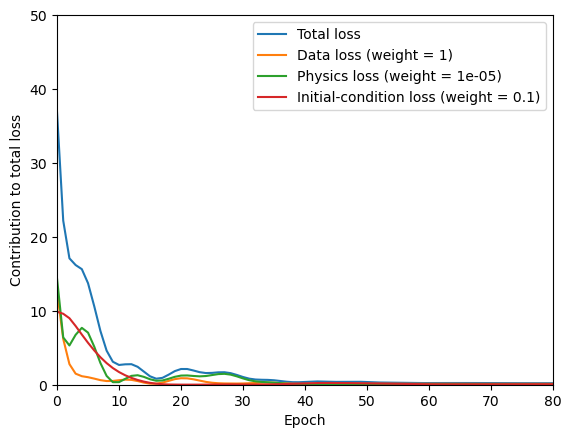

Last recorded total loss: 0.197997
Data contribution:        0.118615
Physics contribution:     0.018281
IC contribution:          0.061101


In [ ]:
#Nu plotter vi så de forskellige bidrag til loss'en over tid, så vi kan se hvordan de forskellige bidrag udvikler sig under træningen.

plt.plot(train_losses, label="Total loss")
plt.plot(data_losses, label="Data loss (weight = 1)")
plt.plot(phys_losses, label="Physics loss (weight = %g)" % lambda_phys)
plt.plot(IC_losses, label="Initial-condition loss (weight = %g)" % lambda_IC)

plt.xlabel("Epoch")
plt.ylabel("Contribution to total loss")
plt.xlim([0, 80])
plt.ylim([0, 50])
plt.legend()
plt.show()

print("Last recorded total loss: %0.6f" % train_losses[-1])
print("Data contribution:        %0.6f" % data_losses[-1])
print("Physics contribution:     %0.6f" % phys_losses[-1])
print("IC contribution:          %0.6f" % IC_losses[-1])

# Måske vi så skulle overveje at give de forskellige bidrag til loss'en forskellige weights, så vi kan få dem til at bidrage mere ligeværdigt til den samlede loss?

In [ ]:
# Nu laver vi en funktion der træner et netværk for givne regularization vægte (lambdaer) og returnerer det trænede netværk så vi kan bruge de trænede netværk til forudsigelser.

def train_pinn(data_input, data_target, colloc_input, lambda_phys, lambda_IC=1.0, num_epochs=1000):
    torch.manual_seed(42) #vi sørger for at de bliver initialiset ens
    net = Net()
    optimizer = optim.Adam(net.parameters(), lr=0.01)
    
    # Training loop
    for e in range(num_epochs):

        optimizer.zero_grad()

        with torch.no_grad():
            # Calculate loss. (vha. den loss funktion vi definerede tidligere)
            L_data, L_phys, L_IC, tr_loss = loss(
                net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
            )

            # Calculate analytical gradients
            g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads(
                net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
            )

        # Give the gradients to the optimizer
        net.W_1.grad = g_total_W1
        net.W_2.grad = g_total_W2
        net.b_1.grad = g_total_b1
        net.b_2.grad = g_total_b2

        # Update weights
        optimizer.step()
    return net

In [ ]:
# Nu der prøver vi så at træne for to forskellige værdier af lambda_phys (en stor og en lille))
lambda_phys_weak= 0.0001
lambda_phys_strong= 0.1

lambda_IC_weak= 0.1
lambda_IC_strong= 0.1
net_weak= train_pinn(data_input, data_target, colloc_input,lambda_phys_weak, lambda_IC_weak)
net_strong= train_pinn(data_input, data_target, colloc_input, lambda_phys_strong, lambda_IC_strong)



In [ ]:
### Her er jeg så lidt i tivl om hvorvidt det er okay at jeg genererer nyt data til test bare med linspace?? men det gør jeg ihvertfald lige nu fordi jeg jo nu skal have fra 0 til 1 og jeg vil have dem i rækkefølge.

np.random.seed(42)

def data_generator(n_samples=100, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.linspace(0, 1, n_samples+2)[1:-1]
    #np.random.shuffle(t)
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y


data_true = data_generator(n_samples=100, m=1, k=500, mu=5)

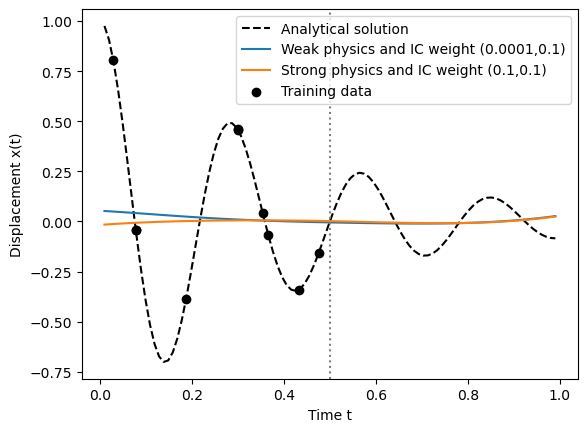

In [ ]:
te_target = torch.from_numpy(data_true[1]).float().reshape(-1, 1)
te_input= torch.from_numpy(data_true[0]).float().reshape(-1, 1)

# så bruger vi de to trænede netværk til at lave forudsigelser på test dataen og sammenligner med den sande test data te_target.
with torch.no_grad():
    te_output_weak = net_weak(te_input).numpy().reshape(-1)
    te_output_strong = net_strong(te_input).numpy().reshape(-1)

t= te_input.numpy().reshape(-1)

# og plot den analytiske løsning, de to forudsigelser og træningsdataen.
plt.plot(t, te_target, "k--", label="Analytical solution")
plt.plot(t, te_output_weak, label="Weak physics and IC weight (%g," % lambda_phys_weak +"%g)" % lambda_IC_weak)
plt.plot(t, te_output_strong, label="Strong physics and IC weight (%g," % lambda_phys_strong + "%g)" % lambda_IC_weak)
plt.scatter(data_data[0], data_data[1], color="black", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()


In [ ]:
## Repeating training from previous task now using torch.autograd.grad to compute the parameter gradients


def train_autograd_pinn(data_input, data_target, colloc_input, lambda_phys, lambda_IC=1.0, num_epochs=1000):
    torch.manual_seed(42) #vi sørger for at de bliver initialiset ens
    net = Net()
    optimizer = optim.Adam(net.parameters(), lr=0.01)


    # Training loop
    for e in range(num_epochs):

        optimizer.zero_grad()

      
        # Calculate loss. (vha. den loss funktion vi definerede tidligere)
        L_data, L_phys, L_IC, tr_loss = loss(
            net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
        )

        # Backpropagation
        tr_loss.backward()

        # Update weights
        optimizer.step()
    
        
    return net

In [ ]:
# Nu træner vi så netværket ved brug af de gradienter

torch.manual_seed(42)
net = Net()
optimizer = optim.Adam(net.parameters(), lr=0.01)

num_epochs = 1000
train_losses_auto = []
data_losses_auto = []
phys_losses_auto = []
IC_losses_auto = []

lambda_phys = 0.1
lambda_IC = 0.1
data_input=torch.from_numpy(data_data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data_data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(data_colloc[0]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

   
    # Calculate loss. (vha. den loss funktion vi definerede tidligere)
    L_data, L_phys, L_IC, tr_loss = loss(
        net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
    )

    # backward
    tr_loss.backward()

    # Update weights
    optimizer.step()
    

    train_losses_auto.append(tr_loss.item())
    data_losses_auto.append(L_data.item())
    phys_losses_auto.append(lambda_phys * L_phys.item())
    IC_losses_auto.append(lambda_IC * L_IC.item())


    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.item()))






Epoch 0, Train Cost: 122789.757812
Epoch 100, Train Cost: 11.015109
Epoch 200, Train Cost: 9.263685
Epoch 300, Train Cost: 7.651814
Epoch 400, Train Cost: 6.080249
Epoch 500, Train Cost: 4.670300
Epoch 600, Train Cost: 3.483548
Epoch 700, Train Cost: 2.536199
Epoch 800, Train Cost: 1.815944
Epoch 900, Train Cost: 1.292359


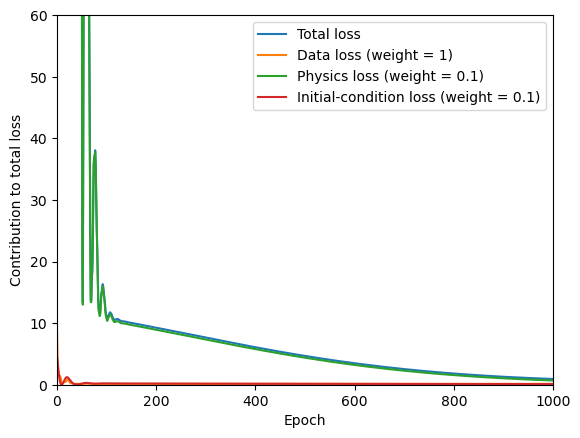

Last recorded total loss: 0.931019
Data contribution:        0.138544
Physics contribution:     0.686211
IC contribution:          0.106264


In [ ]:
#Nu plotter vi så de forskellige bidrag til loss'en over tid, så vi kan se hvordan de forskellige bidrag udvikler sig under træningen.

plt.plot(train_losses_auto, label="Total loss")
plt.plot(data_losses_auto, label="Data loss (weight = 1)")
plt.plot(phys_losses_auto, label="Physics loss (weight = %g)" % lambda_phys)
plt.plot(IC_losses_auto, label="Initial-condition loss (weight = %g)" % lambda_IC)

plt.xlabel("Epoch")
plt.ylabel("Contribution to total loss")
plt.xlim([0, 1000])
plt.ylim([0, 60])
plt.legend()
plt.show()

print("Last recorded total loss: %0.6f" % train_losses_auto[-1])
print("Data contribution:        %0.6f" % data_losses_auto[-1])
print("Physics contribution:     %0.6f" % phys_losses_auto[-1])
print("IC contribution:          %0.6f" % IC_losses_auto[-1])


In [ ]:
## Relativ fejl af gradienter (autograd vs. analytical) ved initialisering 


torch.manual_seed(42)
net=Net()

## analytic gradients

with torch.no_grad():
    # Calculate analytical gradients
    g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads(
        net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
    )

# Calculate loss. (vha. den loss funktion vi definerede tidligere)
L_data, L_phys, L_IC, tr_loss = loss(
    net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
)


## automatic gradients

grads_autograd = torch.autograd.grad(tr_loss, (net.W_1, net.W_2, net.b_1, net.b_2))




rel_error_W1 = (
    torch.linalg.norm(g_total_W1-grads_autograd[0])
    / torch.linalg.norm(grads_autograd[0])
)

rel_error_W2 = (
    torch.linalg.norm(g_total_W2-grads_autograd[1])
    / torch.linalg.norm(grads_autograd[1])
)

rel_error_b1 = (
    torch.linalg.norm(g_total_b1-grads_autograd[2])
    / torch.linalg.norm(grads_autograd[2])
)

rel_error_b2 = (
    torch.linalg.norm(g_total_b2-grads_autograd[3])
    / torch.linalg.norm(grads_autograd[3])
)


print(rel_error_W1,rel_error_W2,rel_error_b1,rel_error_b2)





tensor(2.1732e-07) tensor(1.2166e-07) tensor(1.3175e-07) tensor(8.8151e-08)


In [ ]:
# Nu der prøver vi så at træne for to forskellige værdier af lambda_phys (en stor og en lille))

## argumenter for vores valg af lambda. phys dominerer voldsomt, så hvis man overhovedet skal se en ændring i lambda for IC skal de være langt større end for phys
lambda_phys_weak= 0.00000001
lambda_phys_strong= 0.00001

lambda_IC_weak= 0.001
lambda_IC_strong= 1


net_weak= train_autograd_pinn(data_input, data_target, colloc_input, lambda_phys_weak, lambda_IC_weak)
net_strong= train_autograd_pinn(data_input, data_target, colloc_input, lambda_phys_strong, lambda_IC_strong)

In [ ]:
### Her er jeg så lidt i tivl om hvorvidt det er okay at jeg genererer nyt data til test bare med linspace?? men det gør jeg ihvertfald lige nu fordi jeg jo nu skal have fra 0 til 1 og jeg vil have dem i rækkefølge.

np.random.seed(42)

def data_generator(n_samples=100, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.linspace(0, 1, n_samples+2)[1:-1]
    #np.random.shuffle(t)
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y


data_true = data_generator(n_samples=100, m=1, k=500, mu=5)

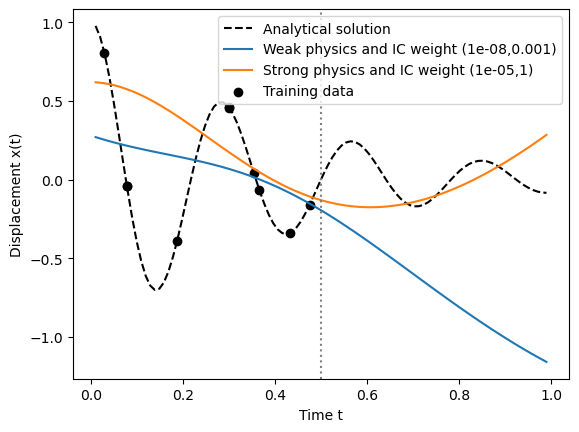

In [ ]:
te_target = torch.from_numpy(data_true[1]).float().reshape(-1, 1)
te_input= torch.from_numpy(data_true[0]).float().reshape(-1, 1)

# så bruger vi de to trænede netværk til at lave forudsigelser på test dataen og sammenligner med den sande test data te_target.
with torch.no_grad():
    te_output_weak = net_weak(te_input).numpy().reshape(-1)
    te_output_strong = net_strong(te_input).numpy().reshape(-1)

t= te_input.numpy().reshape(-1)

# og plot den analytiske løsning, de to forudsigelser og træningsdataen.
plt.plot(t, te_target, "k--", label="Analytical solution")
plt.plot(t, te_output_weak, label="Weak physics and IC weight (%g," % lambda_phys_weak + "%g)" % lambda_IC_weak)
plt.plot(t, te_output_strong, label="Strong physics and IC weight (%g," % lambda_phys_strong + "%g)" % lambda_IC_strong)
plt.scatter(data_data[0], data_data[1], color="black", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()


In [ ]:
## task 2.7
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def data_generator(n_samples=10, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.sort(np.random.uniform(0, 0.5, n_samples))
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y 

data_hard_data = data_generator(n_samples=10, m=1, k=500, mu=5)

np.random.seed(42)

def data_generator(n_samples=10, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.linspace(0,1, n_samples+2)[1:-1]
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 


    return t, y 

data_hard_colloc = data_generator(n_samples=10, m=1, k=500, mu=5)


In [ ]:

def loss_hard(net, data_input, data_target, colloc_input, lambda_phys=1.0):

    data_out= net(data_input)
    colloc_out=net(colloc_input)

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    a=F.linear(colloc_input, W1, b1)

    L_data= nn.MSELoss()(torch.ones_like(data_out)+data_out*data_input**2,data_target)

    tanh_a= torch.tanh(a)
    tanh_a_d= 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d

    x_d= (W2 * tanh_a_d) @ W1
    x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

    x_hat= colloc_out*colloc_input**2 +torch.ones_like(colloc_out)
    x_d_hat= 2*colloc_input*colloc_out + x_d*colloc_input**2
    x_dd_hat= 2*colloc_out + 4*x_d*colloc_input + x_dd*colloc_input**2

    residual = x_dd_hat + 5*x_d_hat + 500*x_hat

    L_phys = nn.MSELoss()(residual, torch.zeros_like(residual))


    L_total= L_data + lambda_phys*L_phys 

    return L_data, L_phys, L_total

In [ ]:
def analytical_grads_hard(net, data_input, data_target, colloc_input,
                     lambda_phys=1.0):

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    data_out = net(data_input)
    colloc_out = net(colloc_input)

    a = F.linear(colloc_input, W1, b1)
    b = F.linear(data_input, W1, b1)

    tanh_a = torch.tanh(a)
    tanh_a_d = 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d
    tanh_a_ddd = -2*tanh_a_d**2 - 2*tanh_a*tanh_a_dd

    tanh_b = torch.tanh(b)
    tanh_b_d = 1 - tanh_b**2

    x_d= (W2 * tanh_a_d) @ W1
    x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

    x_hat= colloc_out*colloc_input**2 +torch.ones_like(colloc_out)
    x_d_hat= 2*colloc_input*colloc_out + x_d*colloc_input**2
    x_dd_hat= 2*colloc_out + 4*x_d*colloc_input + x_dd*colloc_input**2


    residual = x_dd_hat + 5*x_d_hat + 500*x_hat

    residual = (2+10*colloc_input+500*colloc_input**2)*colloc_out + (colloc_input**2)*x_dd + (4*colloc_input+ 5*colloc_input**2)*x_d + 500

    ## gradient of loss w.r.t W1

    t = colloc_input
    t_1 = data_input

    r1_d_W1 = t**2 * (W2 * tanh_a_dd * W1.T + W1.T * (W2 * tanh_a_dd + W2 * tanh_a_ddd * t * W1.T))

    r2_d_W1 = (4*t + 5*t**2) * (W2*tanh_a_d + W2*tanh_a_dd*t*W1.T)

    r3_d_W1 = (2 + 10*t + 500*t**2) * ( W2*tanh_a_d*t)

    residual_d_W1 = r1_d_W1 + r2_d_W1 + r3_d_W1


    g_data_W1 = 2 * torch.mean(((torch.ones_like(data_out)+data_out*t_1**2) - data_target) * (t_1**2*W2 * tanh_b_d) * data_input, dim=0).reshape_as(W1)
    g_phys_W1 = 2 * torch.mean(residual*residual_d_W1, dim=0).reshape_as(W1)


    g_total_W1 = g_data_W1 + lambda_phys*g_phys_W1 
    

    ## gradient of loss w.r.t W2

    r1_d_W2 = t**2 * (W1.T**2 * tanh_a_dd)
    r2_d_W2 = (4*t + 5*t**2)* (tanh_a_d*W1.T)
    r3_d_W2 = (2 + 10*t + 500*t**2)* tanh_a

    residual_d_W2 = r1_d_W2 + r2_d_W2 + r3_d_W2

    g_data_W2 = 2 * torch.mean(((torch.ones_like(data_out)+data_out*t_1**2) - data_target) * t_1**2*tanh_b, dim=0).reshape_as(W2)
    g_phys_W2 = 2 * torch.mean(residual*residual_d_W2, dim=0).reshape_as(W2)

    g_total_W2 = g_data_W2 + lambda_phys*g_phys_W2 
    

    ## gradient of loss w.r.t b1

    r1_d_b1 = t**2 * (W1.T**2 * W2 * tanh_a_ddd)
    r2_d_b1 = (4*t + 5*t**2) * (W2*tanh_a_dd*W1.T)
    r3_d_b1 = (2 + 10*t + 500*t**2)* (W2*tanh_a_d)

    residual_d_b1 = r1_d_b1 + r2_d_b1 + r3_d_b1

    g_data_b1 = 2 * torch.mean(
        ((torch.ones_like(data_out)+data_out*t_1**2) - data_target) * t_1**2*W2*tanh_b_d, dim=0
    ).reshape_as(b1)
    g_phys_b1 = 2 * torch.mean(residual*residual_d_b1, dim=0).reshape_as(b1)

    

    g_total_b1 = g_data_b1 + lambda_phys*g_phys_b1
    

    ## gradient of loss w.r.t b2

    r1_d_b2 = 0
    r2_d_b2 = 0
    r3_d_b2 = (2 + 10*t + 500*t**2)*1

    residual_d_b2 = r1_d_b2 + r2_d_b2 + r3_d_b2

    g_data_b2 = 2 * torch.mean(((torch.ones_like(data_out)+data_out*t_1**2) - data_target)*t_1**2, dim=0)
    g_phys_b2 = 2 * torch.mean(residual*residual_d_b2, dim=0)


    g_total_b2 = g_data_b2 + lambda_phys*g_phys_b2 

    return g_total_W1, g_total_W2, g_total_b1, g_total_b2

In [ ]:

net = Net()
optimizer = optim.Adam(net.parameters(), lr=0.01)

num_epochs = 1000
train_losses = []
data_losses = []
phys_losses = []


lambda_phys = 0.1


data_input=torch.from_numpy(data_hard_data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data_hard_data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(data_hard_colloc[0]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    with torch.no_grad():
        # Calculate loss. (vha. den loss funktion vi definerede tidligere)
        L_data, L_phys, tr_loss = loss_hard(
            net, data_input, data_target, colloc_input, lambda_phys
        )

        # Calculate analytical gradients
        g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads_hard(
            net, data_input, data_target, colloc_input, lambda_phys
        )

    # Give the gradients to the optimizer
    net.W_1.grad = g_total_W1
    net.W_2.grad = g_total_W2
    net.b_1.grad = g_total_b1
    net.b_2.grad = g_total_b2

    # Update weights
    optimizer.step()
    

    train_losses.append(tr_loss.numpy().reshape(()))
    data_losses.append(L_data.numpy())
    phys_losses.append(lambda_phys * L_phys.numpy())

    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.numpy()))

Epoch 0, Train Cost: 99387.343750
Epoch 100, Train Cost: 5214.306641
Epoch 200, Train Cost: 4590.672852
Epoch 300, Train Cost: 3690.774658
Epoch 400, Train Cost: 3101.273438
Epoch 500, Train Cost: 2695.183838
Epoch 600, Train Cost: 2398.298584
Epoch 700, Train Cost: 2168.175049
Epoch 800, Train Cost: 1983.730835
Epoch 900, Train Cost: 1831.871826


In [ ]:
# Nu laver vi en funktion der træner et netværk for givne regularization vægte (lambdaer) og returnerer det trænede netværk så vi kan bruge de trænede netværk til forudsigelser.

def train_pinn_hard(data_input, data_target, colloc_input, lambda_phys, num_epochs=1000):
    torch.manual_seed(42) #vi sørger for at de bliver initialiset ens
    net = Net()
    optimizer = optim.Adam(net.parameters(), lr=0.01)
    
    # Training loop
    for e in range(num_epochs):

        optimizer.zero_grad()

        with torch.no_grad():
            # Calculate loss. (vha. den loss funktion vi definerede tidligere)
            L_data, L_phys, tr_loss = loss_hard(
                net, data_input, data_target, colloc_input, lambda_phys
            )

            # Calculate analytical gradients
            g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads_hard(
                net, data_input, data_target, colloc_input, lambda_phys
            )

        # Give the gradients to the optimizer
        net.W_1.grad = g_total_W1
        net.W_2.grad = g_total_W2
        net.b_1.grad = g_total_b1
        net.b_2.grad = g_total_b2

        # Update weights
        optimizer.step()
    return net

In [ ]:
# Nu der prøver vi så at træne for to forskellige værdier af lambda_phys (en stor og en lille))
lambda_phys_weak_hard= 0.000000001
lambda_phys_strong_hard= 1
net_weak_hard= train_pinn_hard(data_input, data_target, colloc_input, lambda_phys_weak_hard, num_epochs)
net_strong_hard= train_pinn_hard(data_input, data_target, colloc_input, lambda_phys_strong_hard, num_epochs)

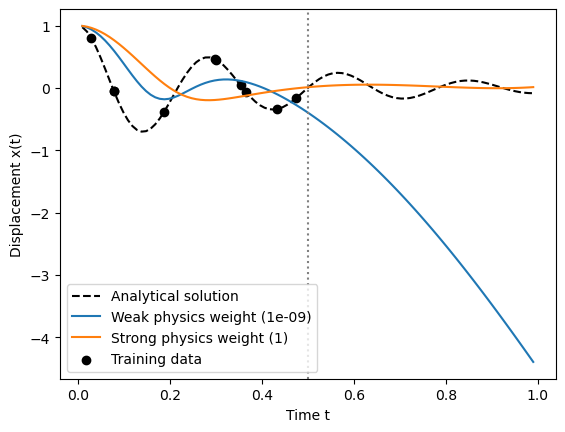

In [ ]:
te_target = torch.from_numpy(data_true[1]).float().reshape(-1, 1)
te_input= torch.from_numpy(data_true[0]).float().reshape(-1, 1)

# så bruger vi de to trænede netværk til at lave forudsigelser på test dataen og sammenligner med den sande test data te_target.
with torch.no_grad():
    te_output_weak_hard = net_weak_hard(te_input).numpy().reshape(-1)
    te_output_strong_hard = net_strong_hard(te_input).numpy().reshape(-1)

t= te_input.numpy().reshape(-1)

# og plot den analytiske løsning, de to forudsigelser og træningsdataen.
plt.plot(t, te_target, "k--", label="Analytical solution")
plt.plot(t, te_output_weak_hard*t**2+1, label="Weak physics weight (%g)" % lambda_phys_weak_hard)
plt.plot(t, te_output_strong_hard*t**2+1, label="Strong physics weight (%g)" % lambda_phys_strong_hard)
plt.scatter(data_hard_data[0], data_hard_data[1], color="black", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()